# Homework 09: Quadratic assignment, IP algorithms, and least squares

**ISyE 524 — Fall 2026**  
**Due:** Monday, November 16, 2026, at 11:59 p.m. (Madison time).

Complete all three problems. Model factory placement using quadratic assignment,
carry out branch-and-bound and strengthen its relaxation with valid inequalities,
and fit road measurements using a convex quadratic program.
Use the supplied decision-variable definitions. Write each requested formulation
before implementing it in Julia/JuMP with HiGHS. Explain your reasoning and check
solver status and solution availability before reading values.

Submit **one PDF to Gradescope** and mark which pages belong to each problem.
**You will not receive full marks unless you mark the pages.**


## Getting started and written answers

Follow [Assignments and PDF Submission](https://github.com/jlinderoth/isye524-students-julia/blob/main/docs/canvas-assignment-workflow.md). In VS Code, use **Tasks: Run Task** to run **ISyE 524: Update course repository**, then **ISyE 524: Start an assignment from its template**, entering `hw09`. Open `student-work/hw09/hw09.ipynb`. An existing working copy will not be overwritten.

For **every written part**, type LaTeX mathematics in Markdown or insert a clear photograph/scan of handwritten work. Include the answer and reasoning together and label the subparts; no duplicate transcription is required. Julia/JuMP implementations belong in code cells.

Use `$x_1 \geq 0$` for inline mathematics and `$$x_1+x_2\leq5$$` for display mathematics. Run the Markdown cell to render it.

For handwritten work, edit a Markdown cell in VS Code, drag in a cropped PNG/JPEG, and choose **Insert Image as Attachment**. Alternatively, put the image beside your working notebook under `student-work/hw09/images/` and insert `![My answer](images/problem1.png)`. Keep external images with the notebook. See [Images and handwritten work](https://github.com/jlinderoth/isye524-students-julia/blob/main/docs/assignments.md#images-and-handwritten-work).

Back up `student-work/hw09/` separately; Git does not back up your answers or images. After completing the notebook, export it with the course PDF task, inspect `submissions/hw09.pdf` for readable mathematics, tables, outputs, and images, and submit that PDF to Gradescope.


## Computational setup

Use the course Julia environment. All numerical data are included below; no
separate data files are needed. The supplied setup, data, and helper cells run
without unfinished answers. In Problem 2, use the helper to solve individual
**continuous LP relaxations** and make the branching and pruning decisions
yourself. You do not need to program a branch-and-bound solver.

AI tools may help debug your own code, explain syntax or error messages, and
critique your work. They should not replace constructing your formulation,
implementation, or written solution. Complete the required collaboration and
LLM-use statement at the end.


In [1]:
using JuMP, HiGHS, LinearAlgebra, NamedArrays, Printf
import MathOptInterface as MOI


## 1: Peeps production in the Lehigh Valley

Peeps production requires four factories. Each factory must be located in one
of seven cities, with at most one factory in each city. Let
$I=\{1,2,3,4\}$ be the factories and $J=\{A,B,C,D,E,F,G\}$ the cities:
Allentown, Bethlehem, Catasauqua, Durham, Easton, Freemansburg, and Glendon,
respectively. The distance $d_{j\ell}$ between cities is measured in miles.

| City | A | B | C | D | E | F | G |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| A | 0 | 6.1 | 15.2 | 17.0 | 16.8 | 8.4 | 16.6 |
| B | 6.1 | 0 | 7.6 | 16.0 | 11.3 | 2.2 | 11.9 |
| C | 15.2 | 7.6 | 0 | 22.0 | 17.3 | 10.2 | 16.7 |
| D | 17.0 | 16.0 | 22.0 | 0 | 12.1 | 14.8 | 7.2 |
| E | 16.8 | 11.3 | 17.3 | 12.1 | 0 | 9.4 | 2.9 |
| F | 8.4 | 2.2 | 10.2 | 14.8 | 9.4 | 0 | 9.2 |
| G | 16.6 | 11.9 | 16.7 | 7.2 | 2.9 | 9.2 | 0 |

The following table gives $f_{ik}$, the tons of manufacturing product shipped
**from factory $i$ to factory $k$ each month**. These are directed flows:
for example, the shipment from 1 to 2 is separate from the shipment from 2 to 1.
Every listed shipment travels directly between the cities of its two factories.
Transportation costs $1 per ton-mile. Ignore factory construction costs.

| From/to factory | 1 | 2 | 3 | 4 |
| --- | ---: | ---: | ---: | ---: |
| 1 | 0 | 3 | 2 | 9 |
| 2 | 5 | 0 | 1 | 2 |
| 3 | 10 | 4 | 0 | 2 |
| 4 | 1 | 6 | 3 | 0 |

Use these binary decision variables:

- $x_{ij}=1$ if factory $i\in I$ is assigned to city $j\in J$, and 0 otherwise.
- $z_{ijk\ell}=1$ if both $x_{ij}=1$ and $x_{k\ell}=1$, and 0 otherwise,
  for $i,k\in I$ and $j,\ell\in J$.

### 1(a): Formulate and linearize

First write the quadratic transportation-cost objective using $x$, together
with the assignment constraints and variable domains. Explain whether a
factor of $1/2$ belongs in this objective.

Then write a complete mixed-integer **linear** formulation using $x$ and $z$.
Include all three linking inequalities that enforce
$z_{ijk\ell}=x_{ij}x_{k\ell}$. Explain why the city constraints differ from
the factory constraints, and why the linking inequalities represent the product.


In [3]:
I = 1:4
J = [:A, :B, :C, :D, :E, :F, :G]
city_name = Dict(zip(J, ["Allentown", "Bethlehem",
                       "Catasauqua", "Durham", "Easton",
                       "Freemansburg", "Glendon"]))
d_numbers = [
     0   6.1 15.2 17.0 16.8  8.4 16.6
     6.1 0    7.6 16.0 11.3  2.2 11.9
    15.2 7.6  0   22.0 17.3 10.2 16.7
    17.0 16.0 22.0 0   12.1 14.8  7.2
    16.8 11.3 17.3 12.1 0    9.4  2.9
     8.4 2.2 10.2 14.8 9.4   0    9.2
    16.6 11.9 16.7 7.2  2.9  9.2  0
]
f_numbers = [0 3 2 9; 5 0 1 2; 10 4 0 2; 1 6 3 0]
d = NamedArray(d_numbers, (J, J))
f = NamedArray(f_numbers, (collect(I), collect(I)));


**Your formulations and explanation:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]

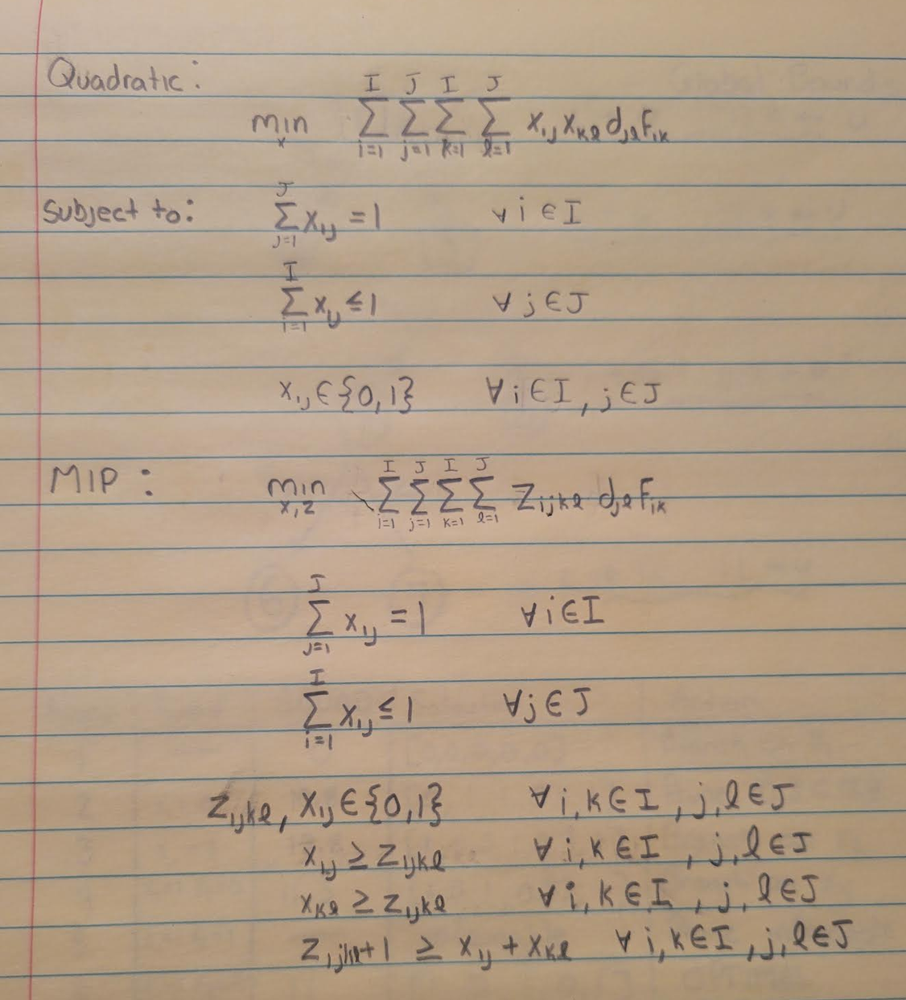

The factor of 1/2 is not needed in the objective becasue the summations sum over locations twice due to the need to consider to and from travel. Because the flow is directed and different in each direction we need to consider both directions of travel.

The cities constraint must be a $ \leq 1$ constraint becasue we dont have enough factories to fill each city.  Thus some cities will have 0 factories. On the other hand we will not have a factory with 0 cities associated with it, thus its constraint must be $=1$.    The added constraint must be equivelent to $z_{i,j,k,l}=x_{i,j}*x_{k,l}$ (which means z must be 1 when both x's are 1 and vis versa)and the first two $x_{i,j} \geq z_{i,j,k,l}$ and $x_{k,l} \geq z_{i,j,k,l}$ force $x_{i,j}$ and $x_{k,l}$ to be 1 when $z_{i,j,k,l}$ is 1 and the last constraint $x_{i,j}+_{k,l} \leq z_{i,j,k,l} +1$ forces the $x_{i,j}$ and $x_{k,l}$ to both be 1 when $z_{i,j,k,l}$ is 1. 

### 1(b): Solve and interpret

Implement the linear formulation using `x[i,j]` and `z[i,j,k,l]`.
Report the city chosen for each factory and the minimum monthly transportation
cost in dollars. Explain briefly how the placement reflects the interfactory flows.


In [14]:
# Build and solve your linear formulation here.

m=Model(HiGHS.Optimizer)

@variable(m, x[I,J], Bin)
@variable(m, z[I,J,I,J], Bin)

@constraint(m, factory[i in I],sum(x[i,j] for j in J)==1)
@constraint(m,city[j in J],sum(x[i,j] for i in I)<=1)
@constraint(m, [i in I, j in J, k in I, l in J], x[i, j] >= z[i, j, k, l])
@constraint(m, [i in I, j in J, k in I, l in J], x[k, l] >= z[i, j, k, l])
@constraint(m, [i in I, j in J, k in I, l in J], x[i, j] +x[k,l] <= z[i, j, k, l]+1)

@objective(m,Min,0.5*sum(sum(sum(sum(z[i,j,k,l]*d[j,l]*f[i,k] for l in J) for k in I) for j in J) for i in I))

optimize!(m)
if !is_solved_and_feasible(m; allow_local = false)
    error("No optimal primal solution: $(termination_status(m)), $(primal_status(m))")
end

println(termination_status(m))

println("Minimum cost: ", objective_value(m), " dollars" )

for i in I
    for j in J
        if value(x[i,j]) > 0.5
            println("Factory ", i, " is in city ", j)
        end
    end
end



Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
MIP has 2363 rows; 812 cols; 5516 nonzeros; 812 integer variables (812 binary)
Coefficient ranges:
  Matrix  [1e+00, 2e+00]
  Cost    [1e+00, 1e+02]
  Bound   [1e+00, 1e+00]
  RHS     [1e+00, 1e+00]
Presolving model
2363 rows, 784 cols, 5348 nonzeros 0s
1649 rows, 532 cols, 3836 nonzeros 0s
1523 rows, 280 cols, 3584 nonzeros 0s
767 rows, 280 cols, 1820 nonzeros 0s
767 rows, 280 cols, 1820 nonzeros 0s
Presolve reductions: rows 767(-1596); columns 280(-532); nonzeros 1820(-3696) 
Objective function is integral with scale 20

Solving MIP model with:
   767 rows
   280 cols (280 binary, 0 integer, 0 implied int., 0 continuous, 0 domain fixed)
   1820 nonzeros
   Thread count 2 (of 4 threads). Using 1 max workers. Parallel search off

Src: B => Branching; C => Central rounding; F => Feasibili

In [ ]:
# Report each factory location and the monthly cost.

J = [:A, :B, :C, :D, :E, :F, :G]
city_name = Dict(zip(J, ["Allentown", "Bethlehem",
                       "Catasauqua", "Durham", "Easton",
                       "Freemansburg", "Glendon"]))

**Your results and interpretation:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]


Factory 1 should be in Freemansburg, Factory 2 should be in Easton, Factory 3 should be in Bethlehem, and Factory 4 should be in Glendon. This will result in a minimum cost of 166.40 dollars. This makes sence becasue the cost to transport between factory 3 and 1 is substancially greater than any other transport cost so it makes sence that they are closest. The total flow between the factorys in both directions controls where they are placed, factories 3 and 1 have 12 products flowing between them and thus are closes together. Factories 3 and 4,  3 and 2 only have 5 products flowing between them so their distance can be further apart. 

## 2: Branch-and-bound and cutting planes

Consider the binary integer program

$$\begin{aligned}
\max\quad &6x_1+5x_2+3x_3+x_4+2x_5\\
\text{s.t.}\quad
&4x_1-x_3+3x_4+3x_5\le7,\\
&4x_1+3x_2+2x_3+5x_4\le9,\\
&x_1+2x_2-x_3\le1,\\
&x_j\in\{0,1\}\quad(j=1,\ldots,5).
\end{aligned}$$

### 2(a): Carry out branch-and-bound

Start with incumbent $x=(0,0,0,0,0)$, of value $L=0$. Solve node LP
relaxations using the helper below, replacing the binary domains by $0\le x_j\le1$.
Use these rules:

1. At a fractional node that cannot be pruned, branch on the fractional variable
   with the **smallest index**, creating children $x_j=0$ and $x_j=1$.
2. Choose **any currently open node** to process next.
   Each child inherits all variable fixings on its path from the root.
3. Solve the LP when visiting a node. Prune if it is infeasible, its upper bound
   is no larger than the incumbent, or its solution is integral. Update the
   incumbent whenever you find a better integral solution. Use the unrounded
   LP objective values as bounds for this exercise.

Draw the complete tree, with branch restrictions on edges and nodes numbered
in the order their LPs are solved. Give each node's LP solution, objective,
incumbent value after processing, and branching or pruning reason. A tree
plus a separate table is fine. Count the LP solves, including the root.
Your tree, LP-solve count, and global bounds at the checkpoint below may
depend on your node-selection order.

Immediately after finding your **first improving integer solution**, state
the global lower and upper bounds. For an unvisited node, use its parent's
LP bound until you solve that node; the global upper bound is the largest
bound among the open nodes and the incumbent.

Use LP solves to carry out the search yourself. Calling a binary optimizer
alone does not provide the requested tree or reasoning.


In [15]:
function node_lp(fixed=Dict{Int,Int}(); cuts=false)
    m = Model(HiGHS.Optimizer)
    set_silent(m)
    @variable(m, 0 <= x[1:5] <= 1)  # Continuous LP variables.
    @objective(m, Max, 6x[1] + 5x[2] + 3x[3] + x[4] + 2x[5])
    @constraint(m, 4x[1] - x[3] + 3x[4] + 3x[5] <= 7)
    @constraint(m, 4x[1] + 3x[2] + 2x[3] + 5x[4] <= 9)
    @constraint(m, x[1] + 2x[2] - x[3] <= 1)
    for (j, v) in fixed
        @constraint(m, x[j] == v)
    end
    if cuts  # The two inequalities supplied in part 2(b).
        @constraint(m, x[1] + x[2] <= 1)
        @constraint(m, x[1] + x[2] + x[4] + x[5] <= 2)
    end
    optimize!(m)
    status = termination_status(m)
    if status == MOI.INFEASIBLE
        return (status=status, bound=nothing, x=nothing)
    end
    if status != MOI.OPTIMAL || !has_values(m)
        error("LP solve failed: $status")
    end
    return (status=status, bound=objective_value(m), x=value.(x))
end;


Call `node_lp()` for the root. To impose fixings, pass a dictionary such as
`Dict(1 => 0, 5 => 1)`; its entries fix $x_1=0$ and $x_5=1$.
For the strengthened model in part 2(b), use `node_lp(; cuts=true)`.
The return fields are `.status`, `.bound`, and `.x`. Decimal solver values
within $10^{-6}$ of 0 or 1 may be treated as integral.


In [ ]:
# Solve and record the LP at each node you visit.
# Make branching and pruning decisions yourself.


@show node_lp() #1
@show node_lp(Dict(1 => 0)) #2
@show node_lp(Dict(1 => 1)) #3
@show node_lp(Dict(1 => 1, 2=>0)) #4
@show node_lp(Dict(1 => 1, 2=>1))#5
@show node_lp(Dict(1 => 1, 2=>0, 4=>0)) #6
@show node_lp(Dict(1 => 1, 2=>0, 4=>1))#7

node_lp() = (status = OPTIMAL, bound = 13.8, x = [1.0, 0.5, 1.0, 0.3, 1.0])
node_lp(Dict(1 => 0)) = (status = OPTIMAL, bound = 10.8, x = [-0.0, 1.0, 1.0, 0.8, 1.0])
node_lp(Dict(1 => 1)) = (status = OPTIMAL, bound = 13.8, x = [1.0, 0.5, 1.0, 0.3, 1.0])
node_lp(Dict(1 => 1, 2 => 1)) = (status = INFEASIBLE, bound = nothing, x = nothing)
node_lp(Dict(1 => 1, 2 => 0)) = (status = OPTIMAL, bound = 11.333333333333334, x = [1.0, -0.0, 1.0, 0.3333333333333333, 1.0])
node_lp(Dict(1 => 1, 2 => 0, 4 => 0)) = (status = OPTIMAL, bound = 11.0, x = [1.0, -0.0, 1.0, -0.0, 1.0])
node_lp(Dict(1 => 1, 2 => 0, 4 => 1)) = (status = OPTIMAL, bound = 7.0, x = [1.0, 0.0, -0.0, 1.0, -0.0])


(status = OPTIMAL, bound = 7.0, x = [1.0, 0.0, -0.0, 1.0, -0.0])

**Your tree, node table, and global bounds:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]


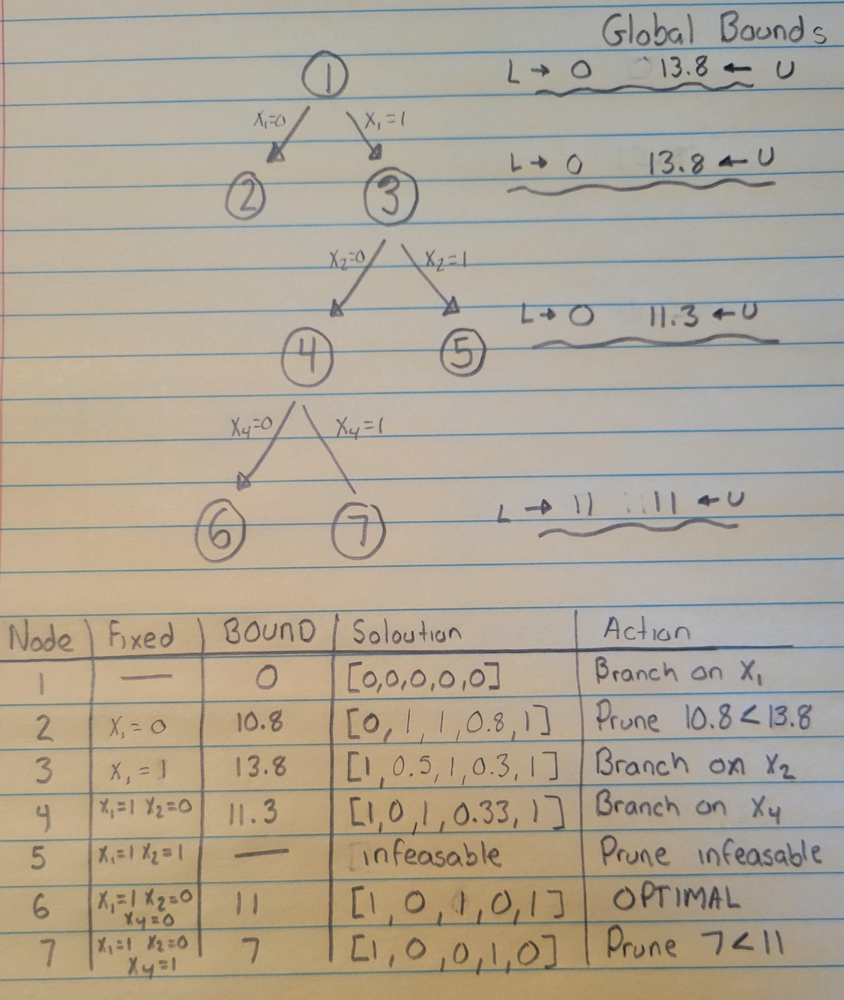


Optimal soloution is 11 with x=[1,0,1,0,1].

### 2(b): Strengthen the relaxation with valid inequalities

Consider

$$x_1+x_2\le1\tag{C1}$$
and
$$x_1+x_2+x_4+x_5\le2.\tag{C2}$$

Prove that each inequality holds for **every feasible binary solution** of the
original model. For (C2), a useful approach is to consider the possibilities for
$(x_1,x_2)$ allowed by (C1). Use the original constraints and binary domains;
checking only one optimal solution does not establish validity.

Evaluate the left side of each cut at the original root LP solution. Then
add both cuts, solve the strengthened root LP, and continue branching if
necessary under the same rules as part 2(a). Report its solution and objective,
the total LP solves for this new search, and the comparison with part 2(a).
Explain why adding valid cuts can improve the LP bound while leaving the
optimal integer value unchanged.


**Your validity proofs and root-point evaluations:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]

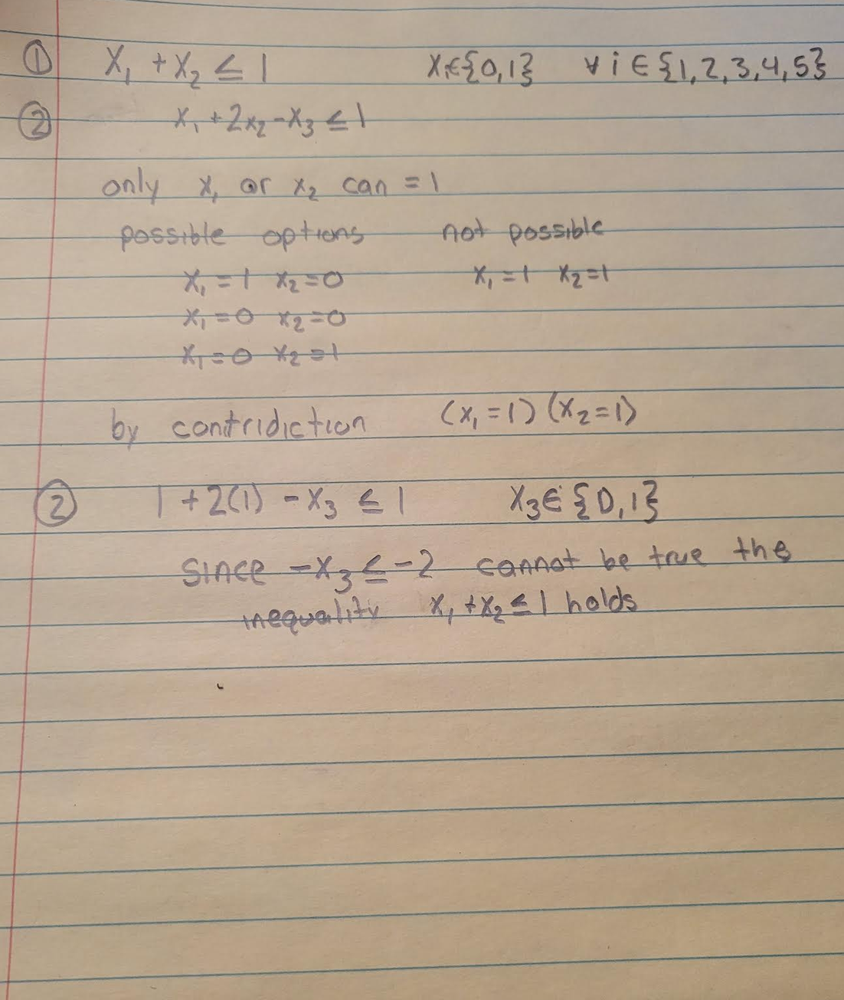


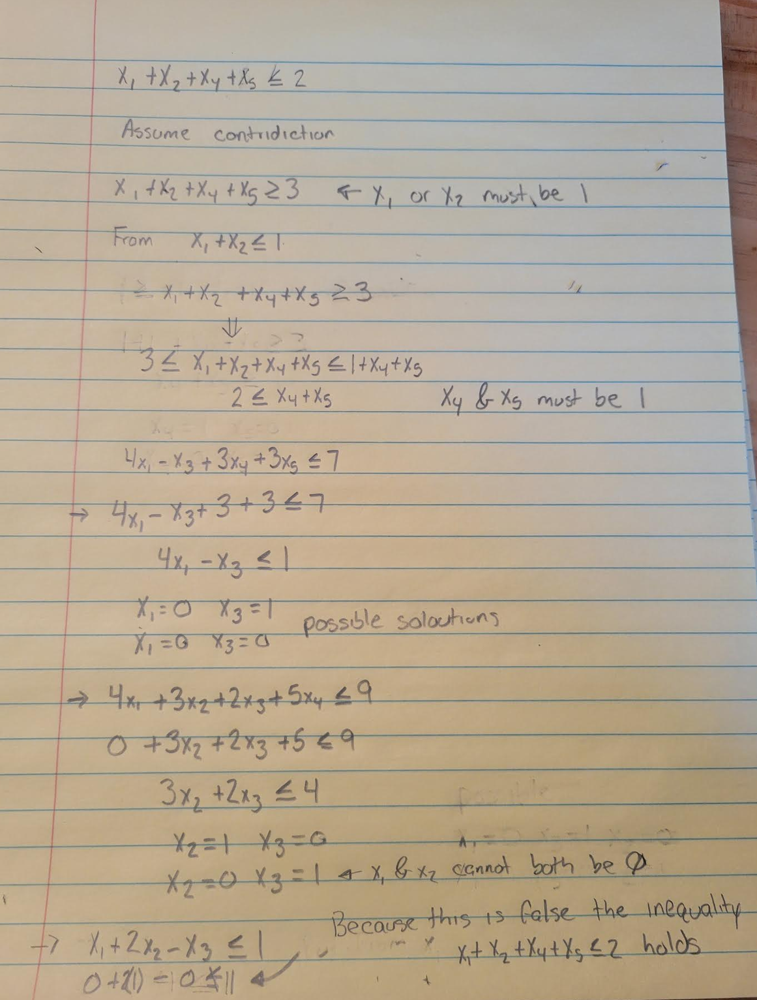

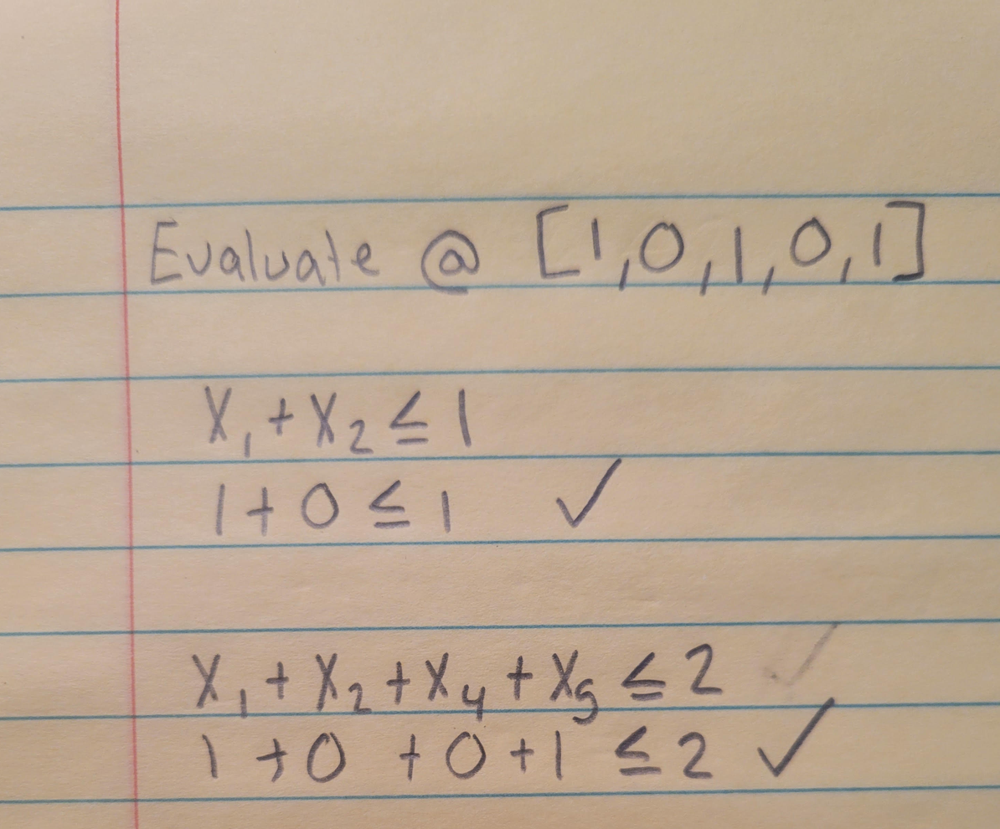

In [31]:
# Solve the strengthened root LP and continue only if needed.

@show node_lp(; cuts=true)


node_lp(; cuts = true) = (status = OPTIMAL, bound = 11.0, x = [1.0, -0.0, 1.0, -0.0, 1.0])


(status = OPTIMAL, bound = 11.0, x = [1.0, -0.0, 1.0, -0.0, 1.0])

**Your comparison and explanation:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]

The optimal soloution is 11 with a solouton of x=[1,0,1,0,1] and only one iteration.
Adding these two cuts makes this LP not reqire any branching. This is because the optimal solution can be found directly using the simplex method. The reason this occurs is that the original constraints included reagion that was not feasable when the intiger constraints are considered and the added constraints/cuts force the feasable region to have feasable integer soloutions lie on the border of the feasable region rather than landing inside the general feasable region.

## 3: Fitting road measurements with a convex QP

Four points $A,B,C,D$ lie in this order along a road. Measurements of distances
along the road contain small errors:

| Measurement | $AD$ | $AC$ | $BD$ | $AB$ | $CD$ |
| --- | ---: | ---: | ---: | ---: | ---: |
| Observed distance (m) | 89 | 67 | 53 | 35 | 20 |

Let $x_1=AB$, $x_2=BC$, and $x_3=CD$ be the fitted segment lengths, in meters.
Use the **unconstrained** least-squares model, $x\in\mathbb{R}^3$.
Give each measurement equal weight.

### 3(a): Construct the fitting model

Write $Ax\approx b$ in the measurement order $AD,AC,BD,AB,CD$, showing the
$5\times3$ matrix $A$ and the vector $b$.
Write the least-squares optimization model minimizing the **sum of squared
residuals**, with residual defined as fitted distance minus observed distance.


In [ ]:
measurements = ["AD", "AC", "BD", "AB", "CD"]
b = [89.0, 67.0, 53.0, 35.0, 20.0];

A=[
    1 1 1;
    1 1 0;
    0 1 1;
    1 0 0;
    0 0 1
]

x1,x2,x3= A\b
r=A*[x1,x2,x3]-b

println("x1: ", x1, " m")
println("x2: ", x2, " m")
println("x3: ", x3, " m")
#println("residual value: ", r)

x1: 35.12499999999999 m
x2: 32.500000000000014 m
x3: 20.62499999999998 m
residual value: [-0.7500000000000284, 0.625, 0.1249999999999929, 0.1249999999999929, 0.6249999999999787]


**Your matrix and formulation:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]

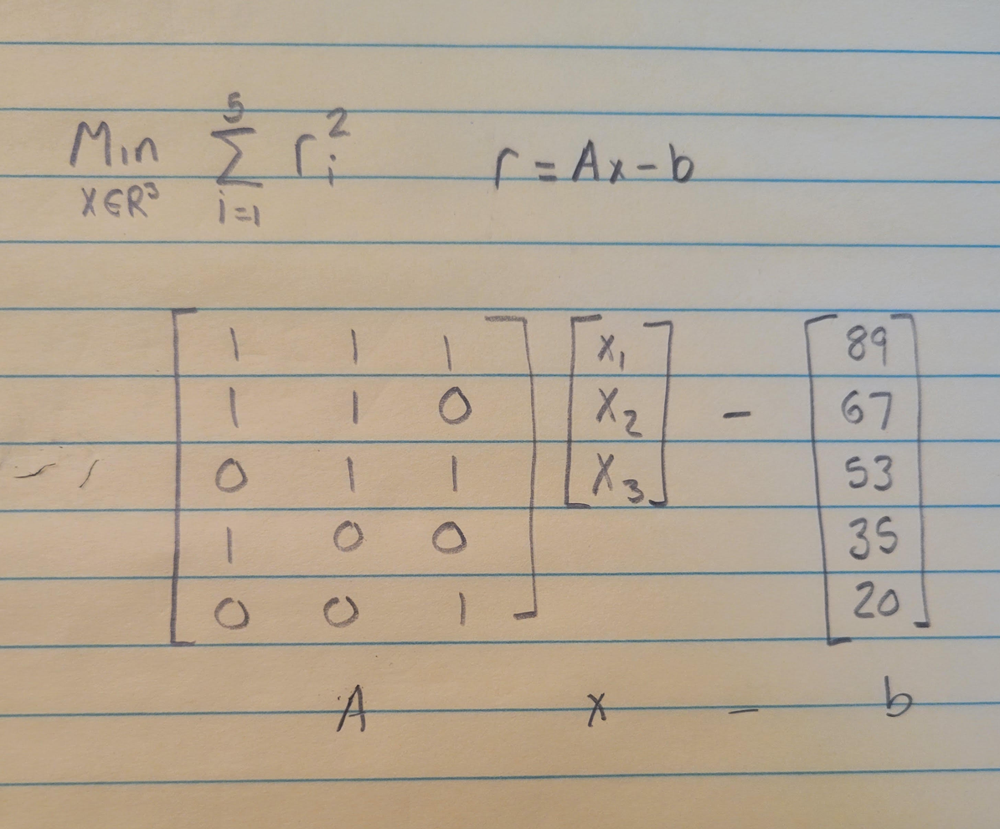

The optimal minimization of sum of least squared residuals is x1=35.125 m, x2=32.5 m, x3=20.625 m.

### 3(b): Identify the quadratic matrix and establish convexity

Expand $\|Ax-b\|_2^2$ as $x^\top Qx+c^\top x+\gamma$, where $Q$ is symmetric,
$c$ is a vector, and $\gamma$ is a scalar. Give formulas and numerical values
for $Q,c,\gamma$.

Using the definition of a PSD matrix, show that $Q\succeq0$. Then determine
whether $Q$ is actually positive definite in this instance and explain the
consequence for uniqueness of the fitted lengths.


**Your quadratic expansion and PSD reasoning:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]

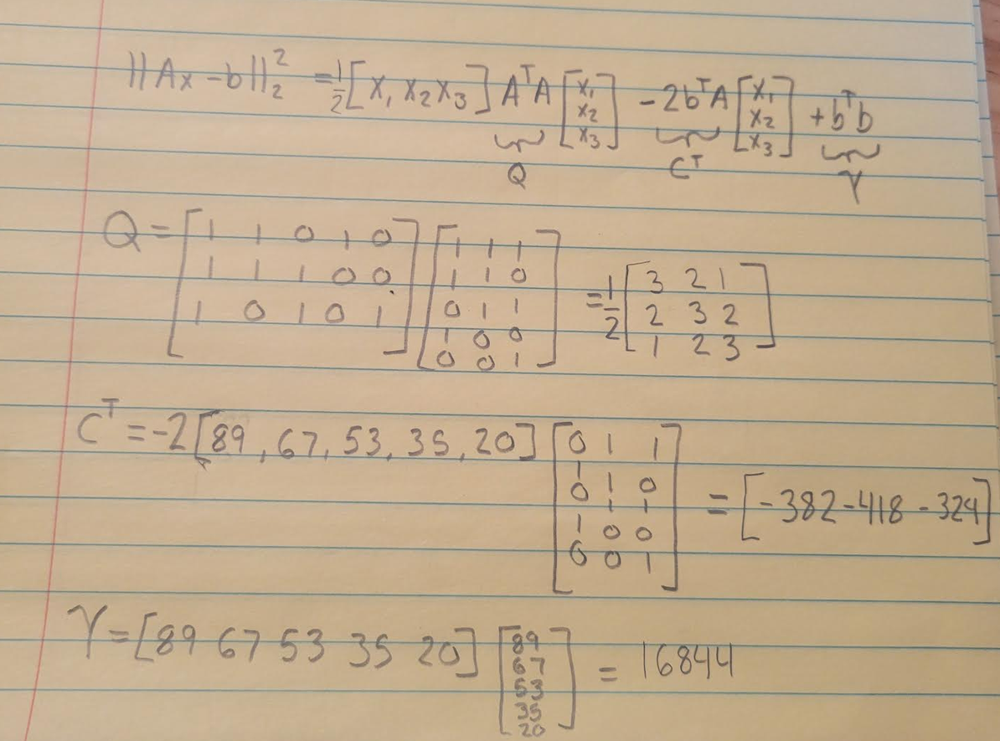

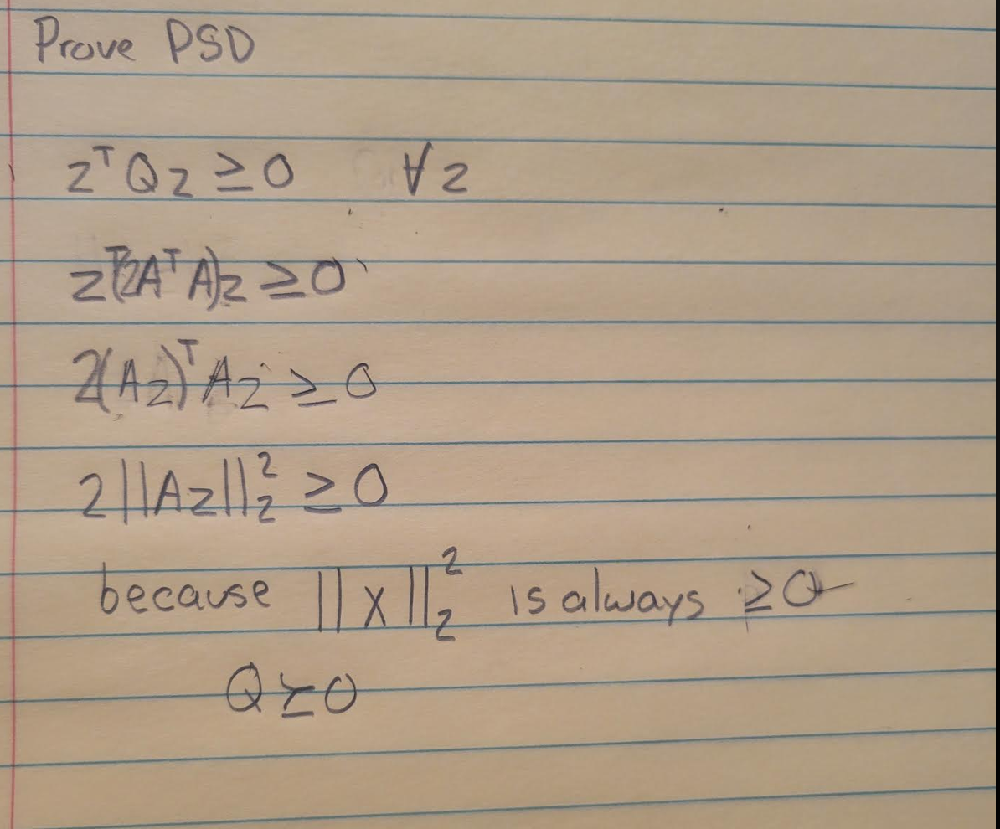

In [42]:
println(eigvals(0.5*(A'*A)))

[0.3138593383654924, 0.9999999999999998, 3.186140661634507]


Eigen values of Q are all positive and Q is symetric. Becasue Q is symentric and positive definite this means that the lengths fited are unique becassue the columns of A are linearly independent.

### 3(c): Solve and report the fit

Implement the least-squares model in JuMP using `x[1:3]` and solve it with
HiGHS. Report the three fitted segment lengths, the five fitted distances,
the five signed residuals in the stated order, and the minimum sum of squared
residuals. Include units.


In [57]:
# Enter your A matrix and formulate and solve the least-squares QP.

least_squares=Model(HiGHS.Optimizer)

@variable(least_squares, x[1:3])
@expression(least_squares, r[i=1:5], sum(A[i,j]*x[j] for j in 1:3) - b[i])
@objective(least_squares, Min, sum(r[i]^2 for i in 1:5))

optimize!(least_squares)
if !is_solved_and_feasible(least_squares; allow_local = false)
    error("No optimal primal solution: $(termination_status(least_squares)), $(primal_status(least_squares))")
end

println(termination_status(least_squares))

println("Minimum sum of squared residuals: ", objective_value(least_squares))
println()

x1,x2,x3= value.(x)
r=A*[x1,x2,x3]-b
b_est=A*[x1,x2,x3]

println("x1: ", value(x[1]), " m")
println("x2: ", value(x[2]), " m")
println("x3: ", value(x[3]), " m")
println("")

println("residual value AD: ", r[1], " m")
println("residual value AC: ", r[2], " m")
println("residual value BD: ", r[3], " m")
println("residual value AB: ", r[4], " m")
println("residual value CD: ", r[5], " m")
println("")

println("AD Distance Estamate: ", b_est[1], " m")
println("AC Distance Estamate: ", b_est[2], " m")
println("BD Distance Estamate: ", b_est[3], " m")
println("AB Distance Estamate: ", b_est[4], " m")
println("CD Distance Estamate: ", b_est[5], " m")


Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
QP has 0 rows; 3 cols; 0 matrix nonzeros; 6 Hessian nonzeros
  Iteration        Objective     NullspaceDim
Model status        : Optimal
Objective value     :  1.3750000000e+00
P-D objective error :  7.2405589753e-05
HiGHS run time      :          0.00
OPTIMAL
Minimum sum of squared residuals: 1.375000000003638

x1: 35.12499958593748 m
x2: 32.499999768750016 m
x3: 20.6249999484375 m

residual value AD: -0.7500006968749915 m
residual value AC: 0.6249993546875032 m
residual value BD: 0.12499971718752079 m
residual value AB: 0.12499958593748062 m
residual value CD: 0.6249999484375017 m

AD Distance Estamate: 88.24999930312501 m
AC Distance Estamate: 67.6249993546875 m
BD Distance Estamate: 53.12499971718752 m
AB Distance Estamate: 35.12499958593748 m
CD Distance Estamate: 20.6249999484375 m

In [ ]:
# Report fitted lengths, distances, and residuals.
# Also report the minimum sum of squared residuals.
measurements = ["AD", "AC", "BD", "AB", "CD"]

**Your results:**

[Type your answer and reasoning here, or insert a clear photograph/scan of handwritten work.]

The minimum sum of squared residuals is 1.375. This is achived when x1=35.125 m x2=32.5 m and x3=20.625 m. The residual values are: 

 -0.75m on AD distance 
 
 0.625 m on AC distance, 
 
 0.125 m on BD distance, 
 
 0.125 m on AB distance 
 
 0.625 m on CD distance. 
 
 This results in the following fitted distances:

AD Distance Estamate: 88.250 m

AC Distance Estamate: 67.625 m

BD Distance Estamate: 53.125 m

AB Distance Estamate: 35.125 m

CD Distance Estamate: 20.625 m

## Collaboration and LLM-use statement — required

Complete this statement as the **very last part of your homework**. Be specific enough that a reader can understand what work you did yourself and how others or LLMs helped you learn.

- **People:** Give the name of every person you collaborated with, identify the problem/subpart you discussed, and explain the nature of the collaboration. If you worked alone, explicitly state that you did not collaborate with anyone.
- **LLMs/tools:** Name every LLM or AI assistant you used and identify the model/version as precisely as available. If the interface did not show a model/version, say so. If you used none, explicitly state that you did not use an LLM or AI assistant.
- **Specific assistance and learning:** For each tool, identify the problem/subpart, describe what you asked it to help with, what suggestions you used or rejected, and how the interaction helped you understand the mathematics or implementation. Explain how you checked the suggestions. “I used ChatGPT for help” is not sufficiently specific.

Disclosure does not replace the requirement that your submitted formulation, implementation, and explanation be your own work and that you understand them.


**People and collaboration:**

[Names, problem/subparts, and what you discussed; or explicitly state that you worked alone.]

I worked alone.

**LLMs/tools and models:**

[Tool names and models/versions, or explicitly state that you used none.]

I used Gemini 4.0 Thining.

**How I used the assistance, what I learned, and how I checked it:**

[Specific details for each tool and relevant problem/subpart; state not applicable if you used none.]

I used the LLM to understand the proper way to fomat @constraint(m, [i in I, j in J, k in K, l in L], x[i, j] >= z[i, j, k, l]) on problem 1. I had't worked with indexing over more than 2 variables so I wasnt sure where to put the extra indexing.  After being given the general format for indexing over more than 2 I was able to apply it to work on 4 indexes. 

I also used it in problem to to assist me in printing the inputs and outputs on my function. This can be done using the Julia @show macro, saving me time typing out each print statment or building a loop for each time I branched.
